Make sure to import "all_csu_scraped_data_combined.parquet" from Raw data files and "transparent_california_no_dup_filtered_csu_salaries.parquet" from /Faculty Data/CSU Data/ transparent_california_no_dup_filtered_csu_salaries.parquet" into the Colab before you start


In [5]:
import pandas as pd

def prepare_names(df):
    df = df.copy()
    # Normalize both directory "Last, First" and payroll "First Last" names.
    # Strip suffixes before reordering so "Smith, John, Jr." stays well formed.
    names = (
        df["name"].astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.replace(r"(?i),?\s+(?:Jr\.?|Sr\.?|II|III|IV)$", "", regex=True)
        .str.replace(r"^([^,]+),\s*([^,]+)$", r"\2 \1", regex=True)
        # Remove middle initials only after converting to First Last order.
        # Keep full middle names, first initials, and compound surnames.
        .str.replace(r"(?<=\S) (?:(?:[A-Za-z]\.?|(?:[A-Za-z]\.){2,}) )+(?=\S)", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )
    df["name"] = names
    tokens = names.str.casefold().str.split()

    df["_match_full"] = tokens.str.join(" ")
    df["_match_first"] = tokens.str[0]
    df["_match_last"] = tokens.str[-1]
    df["_match_count"] = tokens.str.len()

    # Exclude missing or empty names so they cannot match each other.
    return df.loc[df["_match_count"].gt(0)].copy()

csu_pay = pd.read_parquet('content/transparent_california_no_dup_filtered_csu_salaries_2013-2024.parquet')
combined_csu = pd.read_parquet('content/all_csu_scraped_data_combined.parquet')

csu_pay = csu_pay[csu_pay["role"] != "staff"]

pay = prepare_names(csu_pay)
faculty = prepare_names(combined_csu)


# Find candidates with matching first and last tokens.
candidates = pay.merge(
    faculty,
    on=["_match_first", "_match_last"],
    how="inner",
    suffixes=("_transparentCA", "_scraped"),
)

# If token counts are equal, the full names must also match.
keep = (
    candidates["_match_full_transparentCA"].eq(candidates["_match_full_scraped"])
    | candidates["_match_count_transparentCA"].ne(candidates["_match_count_scraped"])
)

joined = (
    candidates.loc[keep]
    .drop(columns=[
        "_match_first",
        "_match_last",
        "_match_full_transparentCA",
        "_match_full_scraped",
        "_match_count_transparentCA",
        "_match_count_scraped",
    ])
    .reset_index(drop=True)
)

joined = joined.drop(columns=["name_transparentCA"]).rename(
    columns={"name_scraped": "name"}
)

joined = joined[["name"] + [col for col in joined.columns if col != "name"]]

print(f"Matched rows: {len(joined):,}")
joined.head(10)


cleaned_columns = [
    "name", "job", "role", "base", "overtime", "other", "totalpay",
    "totalbenefits", "totalpaybenefits", "year_transparentCA",
  "title", "department_scraped", "school", "year_scraped",
    "major", "start_date",
]
cleaned_joined = joined.loc[:, cleaned_columns].copy()
cleaned_joined.to_parquet("content/csu_cleaned_joined_pay_2013-2024.parquet", index=False)
print(f"Saved {len(cleaned_joined):,} cleaned joined rows")



Matched rows: 148,425
Saved 148,425 cleaned joined rows


### Load Data

In [7]:
import polars as pl
import duckdb

raw_df = pl.read_parquet("content/csu_cleaned_joined_pay_2013-2024.parquet")
df = raw_df

### Basic Data Information


In [8]:
df.describe()

statistic,name,job,role,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,title,department_scraped,school,year_scraped,major,start_date
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str
"""count""","""148425""","""148425""","""148425""",148425.0,148425.0,148425.0,148425.0,148425.0,148425.0,148425.0,"""139471""","""145475""","""148425""","""14425""","""306""","""17757"""
"""null_count""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""8954""","""2950""","""0""","""134000""","""148119""","""130668"""
"""mean""",null,null,null,52289.344565,0.860441,5171.268836,57461.609486,23672.358518,81134.258629,2019.545218,null,null,null,null,null,null
"""std""",null,null,null,47047.167934,88.74814,9976.861284,52032.385419,22679.139207,73508.822363,3.241882,null,null,null,null,null,null
"""min""","""Aakash Ahamed""",null,"""clinical_adjunct_faculty""",0.0,0.0,-16941.0,0.0,-24698.0,-5714.0,2013.0,"""ASC""","""""","""CSU Bakersfield""","""""","""Biological Psychology / Behavi…","""1974"""
"""25%""",null,null,null,0.0,0.0,0.0,0.0,0.0,0.0,2017.0,null,null,null,null,null,null
"""50%""",null,null,null,51595.0,0.0,0.0,56595.0,23876.0,81323.0,2020.0,null,null,null,null,null,null
"""75%""",null,null,null,91474.0,0.0,6409.0,98508.0,43164.0,141691.0,2022.0,null,null,null,null,null,null
"""max""","""jody berger""",null,"""trainee""",373144.0,16722.0,205512.0,373144.0,130998.0,496884.0,2024.0,"""World Languages Faculty Adviso…","""the School of Journalism and M…","""Sonoma State University""","""2026""","""Social Psychology""","""2025"""


In [9]:
df.head()

name,job,role,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,title,department_scraped,school,year_scraped,major,start_date
str,cat,str,i32,i32,i32,i32,i32,i32,i16,str,str,str,str,str,str
"""Peter Kilduff""","""department chair - 12 month""","""ladder_faculty""",125029,0,0,125029,46234,171264,2013,"""Professor""","""Department of Apparel Merchand…","""Cal Poly Pomona""",null,null,null
"""Jill Hargis""","""department chair - academic ye…","""ladder_faculty""",70919,0,2990,73910,34181,108091,2013,"""Professor""","""Political Science""","""Cal Poly Pomona""",null,null,null
"""Sarah Lorenzen""","""department chair - academic ye…","""ladder_faculty""",80663,0,13251,93915,30788,124703,2013,"""Professor""","""Architecture""","""Cal Poly Pomona""",null,null,null
"""Lee-Anne Milburn""","""department chair - academic ye…","""ladder_faculty""",102375,0,4173,106548,27705,134254,2013,"""Professor""","""Landscape Architecture""","""Cal Poly Pomona""",null,null,null
"""Dennis Quinn""","""department chair - academic ye…","""ladder_faculty""",75779,0,2064,77843,35798,113641,2013,"""Professor""","""Interdisciplinary General Educ…","""Cal Poly Pomona""",null,null,null


### Role Column
No rows are dropped here. `role` comes from the Transparent California job title.
`filtered_faculty` is the stable input to department bucketing; `faculty_salaries` is the working table.

In [10]:
# Rebuild from the original input so this cell is safe to rerun.
df = duckdb.sql("SELECT DISTINCT * FROM raw_df").pl()
duckdb.sql("CREATE OR REPLACE TABLE filtered_faculty AS SELECT * FROM df")
duckdb.sql("CREATE OR REPLACE TABLE faculty_salaries AS SELECT * FROM filtered_faculty")

Data info after adding roles

In [11]:
df.describe()

statistic,name,job,role,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,title,department_scraped,school,year_scraped,major,start_date
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str
"""count""","""148364""","""148364""","""148364""",148364.0,148364.0,148364.0,148364.0,148364.0,148364.0,148364.0,"""139438""","""145414""","""148364""","""14415""","""306""","""17756"""
"""null_count""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""8926""","""2950""","""0""","""133949""","""148058""","""130608"""
"""mean""",null,null,null,52297.11337,0.860795,5172.595502,57470.70536,23675.674261,81146.670291,2019.545233,null,null,null,null,null,null
"""std""",null,null,null,47049.35337,88.766381,9978.152753,52034.974044,22679.750847,73512.162208,3.241899,null,null,null,null,null,null
"""min""","""Aakash Ahamed""","""cma instructional faculty -cru…","""clinical_adjunct_faculty""",0.0,0.0,-16941.0,0.0,-24698.0,-5714.0,2013.0,"""ASC""","""""","""CSU Bakersfield""","""""","""Biological Psychology / Behavi…","""1974"""
"""25%""",null,null,null,0.0,0.0,0.0,0.0,0.0,0.0,2017.0,null,null,null,null,null,null
"""50%""",null,null,null,51604.0,0.0,0.0,56625.0,23878.0,81346.0,2020.0,null,null,null,null,null,null
"""75%""",null,null,null,91481.0,0.0,6413.0,98521.0,43166.0,141699.0,2022.0,null,null,null,null,null,null
"""max""","""jody berger""","""visiting faculty - academic ye…","""trainee""",373144.0,16722.0,205512.0,373144.0,130998.0,496884.0,2024.0,"""World Languages Faculty Adviso…","""the School of Journalism and M…","""Sonoma State University""","""2026""","""Social Psychology""","""2025"""


In [12]:
df.head()

name,job,role,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,title,department_scraped,school,year_scraped,major,start_date
str,str,str,i32,i32,i32,i32,i32,i32,i16,str,str,str,str,str,str
"""Shelton Murinda""","""instructional faculty - academ…","""ladder_faculty""",69595,0,0,69595,35102,104697,2013,"""Professor""","""Department of Animal & Veterin…","""Cal Poly Pomona""",null,null,null
"""Mark Allen""","""instructional faculty - academ…","""ladder_faculty""",80937,0,0,80937,32333,113270,2013,"""Professor""","""Anthropology Department""","""Cal Poly Pomona""",null,null,null
"""Aaron Estrada""","""instructional faculty - academ…","""ladder_faculty""",62925,0,10444,73369,21212,94581,2013,"""Professor""","""Psychology and Child Developme…","""Cal Poly San Luis Obispo""",null,null,null
"""Benjamin Hoover""","""instructional faculty - academ…","""ladder_faculty""",56659,0,7171,63831,18761,82592,2013,"""Professor""","""Plant Sciences""","""Cal Poly San Luis Obispo""",null,null,null
"""Brady Teufel""","""instructional faculty - academ…","""ladder_faculty""",56577,0,5903,62481,26885,89366,2013,"""Professor""","""Journalism""","""Cal Poly San Luis Obispo""",null,null,null


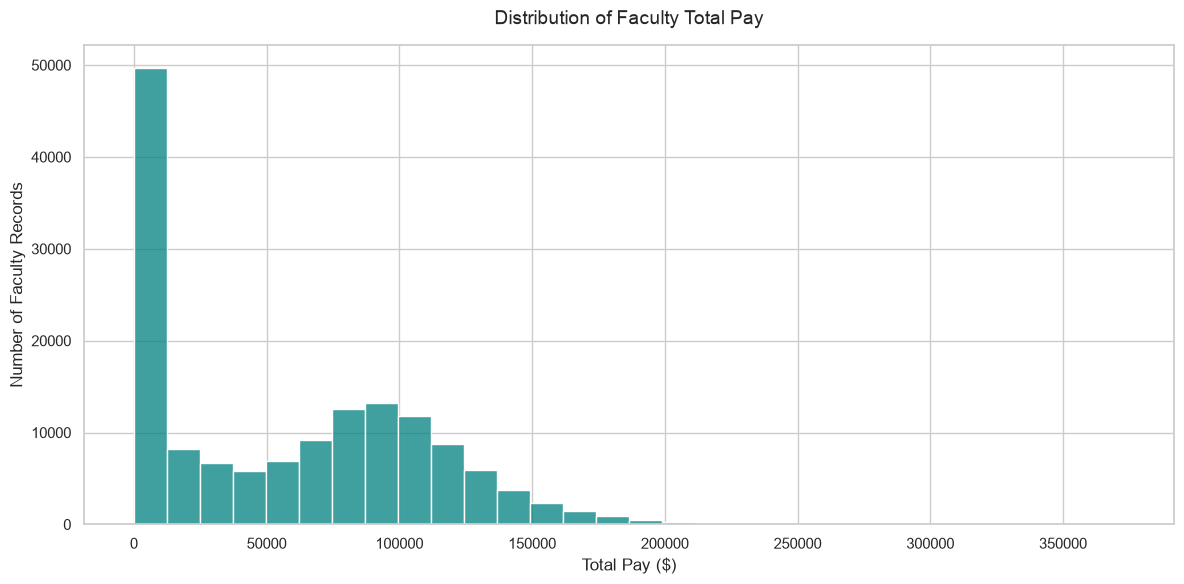

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

pay_df = duckdb.sql("""
SELECT COUNT(*) as count, totalpay AS pay
FROM faculty_salaries
GROUP BY pay
ORDER BY count DESC, pay ASC
""").pl()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create the histogram (bar graph of the distribution)
sns.histplot(
    data=pay_df.to_pandas(),
    x="pay",
    weights="count",
    bins=30,
    color="teal",
    edgecolor="white",
)

plt.title("Distribution of Faculty Total Pay", fontsize=14, pad=15)
plt.xlabel("Total Pay ($)", fontsize=12)
plt.ylabel("Number of Faculty Records", fontsize=12)

ax = plt.gca()

plt.tight_layout()
plt.show()

## Department Cleaning

### Amount of Existing Departments & Titles


In [14]:
duckdb.sql("""
SELECT COUNT(DISTINCT department_scraped) AS unique_departments
FROM faculty_salaries
           """).pl()

unique_departments
i64
1047


In [15]:
duckdb.sql("""
SELECT COUNT(DISTINCT title) AS unique_titles
FROM faculty_salaries
           """).pl()

unique_titles
i64
364


In [16]:
pl.Config.set_tbl_rows(20)

duckdb.sql("""
SELECT COUNT(department_scraped) AS count, department_scraped as department,
FROM faculty_salaries
GROUP BY department
ORDER BY count DESC
LIMIT 20
           """).pl()

count,department
i64,str
5714,"""Psychology"""
3327,"""English"""
3300,"""History"""
3144,"""Mathematics"""
3111,"""Kinesiology"""
2678,"""Biological Sciences"""
2657,"""Management"""
2400,"""Sociology"""
2273,"""Nursing"""


# Depatment Buckets

## Existing Department Buckets

### Calpoly
* Engineering
* Science & Math
* Business
* Agriculture, Food, & Animal Science
* Noyce
* Architecture
* Liberal Arts

### Faculty Pay DB
* Languages
* Communication
* English
* Education
* History
* Philosophy
* Architecture
* Social Sciences
* Public Administration
* Math
* Psychology
* Agriculture
* Biology
* Physics
* Computer Science
* Engineering
* Economics
* Business
* Finance
* Law

## Proposed Department Buckets
* Engineering
* Computer Science
* Science & Mathematics
* Medicine & Heath Sciences
* Business, Economics & Finance
* Agriculture, Food & Animal
* Architecture & Environmental Design
* Humanities & Languages
* Social Sciences & Communication
* Education & Public Administration

In [17]:
pl.Config.set_tbl_rows(20)

duckdb.sql("""
SELECT COUNT(department_scraped) AS count, department_scraped as department,
FROM faculty_salaries
GROUP BY department
ORDER BY count DESC
LIMIT 20
           """).pl()
pl.Config.set_tbl_rows(5)

polars.config.Config

In [18]:
# Analyze Departments
duckdb.sql("""
SELECT DISTINCT department_scraped as department
FROM faculty_salaries
           """).pl()# .write_csv("Departments.csv")

department
str
"""Design, Photography Program"""
"""Nursing"""
"""Political Science"""
…
"""EOP/Stdnt Suprt Srvc"""
"""Mathematics & Statistics; Mech…"


### Creating the Proposed Buckets
Rules use normalized department text and first-match precedence. Education rules precede the
humanities/social rules; `art`/`arts` must be complete words, and there is no generic `studies` rule.
Known subjects are mapped below. Missing or ambiguous departments stay in `Other` for review.
Each run rebuilds from `filtered_faculty`, avoiding stale or duplicated bucket columns.

In [19]:
bucket_sql = r"""
SELECT *, lower(trim(department_scraped)) as department,
CASE
    WHEN
        department ILIKE '%computer%'
        OR department ILIKE '%comp sci%'
        OR department ILIKE '%cmptr sci%'
        OR department ILIKE '%computing%'
        OR department ILIKE '%software%'
        OR department ILIKE '%informatics%'
        OR department ILIKE '%cyber%'
        OR department ILIKE '%data science%'
        OR department ILIKE '%information studies%'
        OR department ILIKE '%school of info%'
        OR department ILIKE '%information systems%'
        OR department ILIKE '%information technology%'
        OR department ILIKE '%decision and information sciences%'
    THEN 'Computer Science'

    WHEN
        department ILIKE '%medicine%'
        OR department ILIKE '%surgery%'
        OR department ILIKE '%vm:%'
        OR department ILIKE '%med:%'
        OR department ILIKE '%nurs%'
        OR department ILIKE '%dentistry%'
        OR department ILIKE '%pharma%'
        OR department ILIKE '%gynecology%'
        OR department ILIKE '%urology%'
        OR department ILIKE '%oncology%'
        OR department ILIKE '%family med%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%ophthalmology%'
        OR department ILIKE '%pathology%'
        OR department ILIKE '%peds%'
        OR department ILIKE '%dermatology%'
        OR department ILIKE '%pediatrics%'
        OR department ILIKE '%anesthesiology%'
        OR department ILIKE '%optometry%'
        OR department ILIKE '%psychiatry%'
        OR department ILIKE '%emerg med%'
        OR department ILIKE '%radiolog%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%anesthes%'
        OR department ILIKE '%public health%'
        OR department ILIKE '%med ed administration%'
        OR department ILIKE '%deans office-school of medicin%'
        OR department ILIKE '%semel institute%'
        OR department ILIKE '%school of med%'
        OR department ILIKE '%dom cardiology%'
        OR department ILIKE '%ophth clinical%'
        OR department ILIKE '%med-campus%'
        OR department ILIKE '%dntl sci%'
        OR department ILIKE '%ob/gyn%'
        OR department ILIKE '%ambulatory%'
        OR department ILIKE '%electronic health record%'
        OR department ILIKE '%electrocardiology%'
        OR department ILIKE '%epidemiology%'
        OR department ILIKE '%otolaryngology%'
        OR department ILIKE '%hematology%'
        OR department ILIKE '%school of public health%'
        OR department ILIKE '%health policy and management%'
        OR department ILIKE '%health sciences%'
        OR department ILIKE '%lppi: instr & research%'
        OR department ILIKE 'dom %'
        OR department ILIKE 'som %'
        OR department ILIKE 'som-%'
        OR department ILIKE '%obgyn%'
        OR department ILIKE '%sfgh%'
        OR department ILIKE 'psych-%'
        OR department ILIKE 'fcm-%'
        OR department ILIKE '%health science%'
        OR department ILIKE '%health care%'
        OR department ILIKE '%health serv%'
        OR department ILIKE '%pub health%'
        OR department ILIKE '%applied health%'
        OR department ILIKE '%kinesiology%'
        OR department ILIKE '%occupational therapy%'
        OR department ILIKE '%audiology%'
        OR department ILIKE '%clinical laboratory%'
        OR department ILIKE '%clinical science%'
        OR department ILIKE '%gerontology%'
        OR department ILIKE '%marital and family therapy%'
    THEN 'Medicine & Health Sciences'

    WHEN
        department ILIKE '%engineer%'
        OR department ILIKE '%engr%'
        OR department ILIKE '%mech%'
        OR department ILIKE '%civil%'
        OR department ILIKE '%aero%'
        OR department ILIKE '%electric%'
        OR department ILIKE '%soe-ams%'
        OR department ILIKE '%chemical%'
        OR department ILIKE '%industrial%'
        OR department ILIKE '%material%'
        OR department ILIKE '%soece-ee-tm-cm%'
        OR department ILIKE '%construction management%'
        OR department ILIKE '%concrete industry%'
    THEN 'Engineering'

    WHEN
        department ILIKE '%plant science%'
        OR department ILIKE '%agricultur%'
        OR department ILIKE '%espm%'
        OR department ILIKE '%nutrition%'
        OR department ILIKE '%inst of environment and sustai%'
        OR department ILIKE '%energy & resources group%'
        OR department ILIKE '%animal%'
        OR department ILIKE '%food science%'
        OR department ILIKE '%food safety%'
        OR department ILIKE '%family and consumer science%'
        OR department ILIKE '%family & consumer science%'
        OR department ILIKE '%forest%'
        OR department ILIKE '%wildlife%'
        OR department = 'agr academic instruction'
    THEN 'Agriculture, Food & Animal'

    WHEN
        department ILIKE '%architec%'
        OR department ILIKE '%planning%'
        OR department ILIKE '%urban%'
        OR department ILIKE '%landscape arch%'
        OR department ILIKE '%environmental%'
        OR department ILIKE '%school of the environment%'
        OR department ILIKE '%env sci%'
        OR department ILIKE '%env studies%'
        OR department ILIKE '%environ s%'
        OR department ILIKE '%interior design%'
    THEN 'Architecture & Environmental Design'

    WHEN
        department ILIKE '%business%'
        OR department ILIKE '%econ%'
        OR department ILIKE '%finance%'
        OR department ILIKE '%management%'
        OR department ILIKE '%marketing%'
        OR department ILIKE '%accounting%'
        OR department ILIKE '%accountancy%'
        OR department ILIKE '%financial%'
        OR department ILIKE '%entrepreneur%'
        OR department ILIKE '%hospitality%'
        OR department ILIKE '%tourism%'
        OR department ILIKE '%decision sciences%'
        OR department ILIKE '%real estate%'
        OR department ILIKE '%technology and operations%'
        OR department ILIKE '%supply chain%'
        OR department ILIKE '%organizational behavior%'
        OR department ILIKE '%organizational leadership%'
        OR department ILIKE '%global innovation and leadership%'
        OR department ILIKE '%recr, hosp%'
        OR department = 'bus'
        OR department ILIKE '%haas core%'
        OR department ILIKE '%technology management program%'
        OR department ILIKE '%grad.sch. int.relat./pac.stud.%'
    THEN 'Business, Economics & Finance'

    WHEN
        department ILIKE '%math%'
        OR regexp_matches(department, '\bstat(istics|istical)?\b')
        OR department ILIKE '%statistics%'
        OR department ILIKE '%bio%'
        OR department ILIKE '%neuro%'
        OR department ILIKE '%phys%'
        OR department ILIKE '%land air & water resources%'
        OR department ILIKE '%climate/atmos sci/phy oceanog%'
        OR department ILIKE '%ocean sciences%'
        OR department ILIKE '%entomology%'
        OR department ILIKE '%physics%'
        OR department ILIKE '%astro%'
        OR department ILIKE '%chem%'
        OR department ILIKE '%sio dep%'
        OR department ILIKE '%molecular, cell%'
        OR department ILIKE '%earth%'
        OR department ILIKE '%oceanic%'
        OR (department ILIKE '%ecology%' AND department NOT ILIKE '%human ecology%')
        OR department ILIKE '%genetics%'
        OR department ILIKE '%igpp%'
        OR department ILIKE '%geosciences%'
        OR department ILIKE '%oceanography%'
        OR department ILIKE '%geology%'
        OR department ILIKE '%viticulture%'
        OR department ILIKE '%nematology%'
        OR department ILIKE '%demography%'
        OR department ILIKE '%geological%'
        OR department ILIKE '%marine science%'
        OR department ILIKE '%marine facilities%'
        OR department ILIKE '%natural sciences%'
        OR department = 'college of sciences'
    THEN 'Science & Mathematics'

    WHEN
        department ILIKE '%education%'
        OR department ILIKE '%public policy%'
        OR department ILIKE '%policy&strategy%'
        OR department ILIKE 'jd program'
        OR department ILIKE '%law%'
        OR department ILIKE '%legal%'
        OR department ILIKE '%journalism%'
        OR department ILIKE '%teaching%'
        OR department ILIKE '%public administration%'
        OR department ILIKE '%public affairs%'
        OR department ILIKE '%pub pol%'
        OR department ILIKE '%homeland security%'
        OR department ILIKE '%student affairs%'
        OR department ILIKE '%learning design%'
        OR department ILIKE '%edleadership%'
        OR department ILIKE '%ed doctorate%'
        OR department ILIKE '%undergrad ed%'
        OR department ILIKE '%extended ed%'
        OR department ILIKE '%instructional technology%'
        OR department ILIKE '%lifelong learning%'
    THEN 'Education & Public Administration'

    WHEN
        department ILIKE '%language%'
        OR department ILIKE '%linguistics%'
        OR department ILIKE '%humanities%'
        OR department ILIKE '%english%'
        OR department ILIKE '%literature%'
        OR department ILIKE '%writing%'
        OR department ILIKE '%history%'
        OR department ILIKE '%philosophy%'
        OR department ILIKE '%french%'
        OR department ILIKE '%spanish%'
        OR department ILIKE '%german%'
        OR department ILIKE '%japanese%'
        OR department ILIKE '%dance%'
        OR department ILIKE '%african%'
        OR department ILIKE '%music%'
        OR department ILIKE '%division of arts%'
        OR department ILIKE '%classics%'
        OR department ILIKE '%film%'
        OR department ILIKE '%visual arts%'
        OR department ILIKE '%theatre%'
        OR department ILIKE '%religious%'
        OR department ILIKE '%theater%'
        OR department ILIKE '%asian lang%'
        OR department ILIKE '%eastern lang%'
        OR department ILIKE '%world arts%'
        OR department ILIKE '%southeast asian%'
        OR department ILIKE '%drama department%'
        OR department ILIKE '%department of chicana%'
        OR department ILIKE '%asian-american%'
        OR department ILIKE '%asian%'
        OR department ILIKE '%studio art%'
        OR regexp_matches(department, '\barts?\b')
        OR department ILIKE '%design program%'
        OR department ILIKE '%rhetoric%'
        OR department ILIKE '%near eastern%'
        OR department ILIKE '%chicano%'
        OR department ILIKE '%department of design%'
        OR department ILIKE '%media%'
        OR department ILIKE '%institute for society and gene%'
        OR department ILIKE '%college of creative studies%'
        OR department ILIKE '%american studies%'
        OR department ILIKE '%italian studies%'
        OR department ILIKE '%native american studies%'
        OR department ILIKE '%performance, play & design%'
        OR department ILIKE '%science & technology studies%'
        OR department ILIKE '%drama%'
        OR department ILIKE '%hispanic%'
        OR department ILIKE '%italian%'
        OR department ILIKE '%scandinavian%'
        OR department ILIKE '%slavic%'
        OR department ILIKE '%greek & roman%'
        OR department ILIKE '%cinema%'
        OR department ILIKE '%religion%'
        OR department ILIKE '%photography%'
        OR department ILIKE '%liberal studies%'
        OR department ILIKE '%lib studies%'
        OR department ILIKE '%arabic%'
        OR department ILIKE '%chinese%'
        OR department ILIKE '%russian%'
        OR department ILIKE '%european studies%'
        OR department ILIKE '%jewish studies%'
        OR regexp_matches(department, '\bdesign\b')
        OR department IN ('engl', 'lang')
    THEN 'Humanities & Languages'

    WHEN
        department ILIKE '%anthropology%'
        OR department ILIKE '%social science%'
        OR department ILIKE '%sociology%'
        OR department ILIKE '%political science%'
        OR department ILIKE '%politics%'
        OR department ILIKE '%ethnic stud%'
        OR department ILIKE '%women%'
        OR department ILIKE '%psychology%'
        OR department ILIKE '%psychological%'
        OR department ILIKE '%cognitive science%'
        OR department ILIKE '%global & intl studies%'
        OR department ILIKE '%soc sci undergrad%'
        OR department ILIKE '%comm%'
        OR department ILIKE '%gender%'
        OR department ILIKE '%child%'
        OR department ILIKE '%geography%'
        OR department ILIKE '%human ecology%'
        OR department ILIKE '%social welfare%'
        OR department ILIKE '%global & international studies%'
        OR department ILIKE '%african am studies%'
        OR department ILIKE '%black studies%'
        OR department ILIKE '%social work%'
        OR department ILIKE '%human services%'
        OR department ILIKE '%human development%'
        OR department ILIKE '%criminal justice%'
        OR department ILIKE '%criminology%'
        OR department ILIKE '%international relations%'
        OR department ILIKE '%social & behavioral%'
        OR department ILIKE '%counseling%'
        OR department ILIKE '%conflict resolution%'
        OR department ILIKE '%peacebuilding%'
        OR department ILIKE '%american indian studies%'
        OR department ILIKE '%native amer studies%'
        OR department ILIKE '%race and resistance%'
        OR department ILIKE '%latina/latino studies%'
        OR department ILIKE '%chicana/o studies%'
        OR department ILIKE '%global studies%'
        OR department ILIKE '%int''l studies%'
        OR department ILIKE '%recreation and leisure%'
        OR department ILIKE '%deaf studies%'
        OR department ILIKE '%labor studies%'
        OR department ILIKE '%labor and employment%'
        OR department ILIKE '%queer studies%'
        OR department IN ('soc', 'swrk')
    THEN 'Social Sciences & Communication'

    ELSE 'Other'
END AS dep_bucket
FROM filtered_faculty
"""

duckdb.sql(f"""
CREATE OR REPLACE TABLE faculty_salaries AS
{bucket_sql}
""")

In [20]:
# Keep unmatched departments, including missing/blank values, for review.
# Do not delete faculty simply because the department mapping is incomplete.
duckdb.sql("""
SELECT dep_bucket, COUNT(*) AS faculty_rows
FROM faculty_salaries
GROUP BY dep_bucket
ORDER BY faculty_rows DESC
""").pl()

dep_bucket,faculty_rows
str,i64
"""Humanities & Languages""",30028
"""Social Sciences & Communicatio…",28674
"""Science & Mathematics""",20116
…,…
"""Agriculture, Food & Animal""",4066
"""Architecture & Environmental D…",3503


In [21]:
pl.Config.set_tbl_rows(11)

# How many departments are accounted for in each bucket
duckdb.sql("""
SELECT COUNT(DISTINCT department_scraped) AS count, dep_bucket
FROM faculty_salaries
GROUP BY dep_bucket
ORDER BY count DESC
           """).pl()

count,dep_bucket
i64,str
230,"""Humanities & Languages"""
163,"""Social Sciences & Communicatio…"
115,"""Other"""
104,"""Business, Economics & Finance"""
102,"""Education & Public Administrat…"
78,"""Science & Mathematics"""
65,"""Engineering"""
61,"""Computer Science"""
55,"""Medicine & Health Sciences"""


In [22]:
# Show every unmatched department, including single-row departments.
pl.Config.set_tbl_rows(30)
duckdb.sql("""
SELECT COUNT(*) AS count, department
FROM faculty_salaries
WHERE dep_bucket = 'Other'
GROUP BY department
ORDER BY count DESC, department
""").pl()

count,department
i64,str
2950,null
1448,"""index.php"""
544,""""""
184,"""lbry"""
161,"""department of curriculum & ins…"
134,"""crgs"""
106,"""department of technology"""
103,"""teacher preparation"""
101,"""academic department"""


### Save the Cleaned Dataset for EDA
Retain `Other` rows for review. Remove only exact duplicates across the exported columns;
keep separate department affiliations/buckets for the same name and school.
The output is sorted by school, name, year, bucket, and original department.

In [25]:
final_df = duckdb.sql("""
SELECT DISTINCT
    year_transparentCA, school, name, title, role,
    department_scraped AS original_department, dep_bucket AS department,
    totalpay AS total_pay, base AS base_pay,
    overtime AS overtime_pay, other AS other_pay
FROM faculty_salaries
ORDER BY school, name, year_transparentCA, role, department, original_department,
         title, total_pay, base_pay, overtime_pay, other_pay
""").pl()

assert final_df.height == final_df.unique().height
final_df.write_parquet("content/csu_depbucket_cleaned_joined_pay_2013-2024.parquet")
final_df.describe()

statistic,year_transparentCA,school,name,title,role,original_department,department,total_pay,base_pay,overtime_pay,other_pay
str,f64,str,str,str,str,str,str,f64,f64,f64,f64
"""count""",148284.0,"""148284""","""148284""","""139358""","""148284""","""145334""","""148284""",148284.0,148284.0,148284.0,148284.0
"""null_count""",0.0,"""0""","""0""","""8926""","""0""","""2950""","""0""",0.0,0.0,0.0,0.0
"""mean""",2019.544448,null,null,null,null,null,null,57498.861732,52323.070756,0.861259,5174.793956
"""std""",3.242021,null,null,null,null,null,null,52034.163307,47048.234671,88.790321,9980.200414
"""min""",2013.0,"""CSU Bakersfield""","""Aakash Ahamed""","""ASC""","""clinical_adjunct_faculty""","""""","""Agriculture, Food & Animal""",0.0,0.0,0.0,-16941.0
"""25%""",2017.0,null,null,null,null,null,null,0.0,0.0,0.0,0.0
"""50%""",2020.0,null,null,null,null,null,null,56719.0,51656.0,0.0,0.0
"""75%""",2022.0,null,null,null,null,null,null,98537.0,91496.0,0.0,6421.0
"""max""",2024.0,"""Sonoma State University""","""jody berger""","""World Languages Faculty Adviso…","""trainee""","""the School of Journalism and M…","""Social Sciences & Communicatio…",373144.0,373144.0,16722.0,205512.0


In [27]:
pl.read_parquet("content/csu_depbucket_cleaned_joined_pay_2013-2024.parquet").head(10)

year_transparentCA,school,name,title,role,original_department,department,total_pay,base_pay,overtime_pay,other_pay
i16,str,str,str,str,str,str,i32,i32,i32,i32
2013,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",148840,97454,0,51386
2014,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",164953,98207,0,66746
2015,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",155361,100861,0,54500
2016,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",146317,102539,0,43778
2016,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""supplemental_teaching_pay""","""Economics""","""Business, Economics & Finance""",0,0,0,0
2017,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",134508,99024,0,35484
2018,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",65309,56174,0,9135
2018,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""supplemental_teaching_pay""","""Economics""","""Business, Economics & Finance""",0,0,0,0
2019,"""CSU Bakersfield""","""Abbas Grammy""","""Professor Emeritus""","""ladder_faculty""","""Economics""","""Business, Economics & Finance""",65619,48893,0,16726


In [31]:
duckdb.sql("""
SELECT COUNT(DISTINCT original_department) AS count, department
FROM final_df
GROUP BY department
""").pl()

count,department
i64,str
230,"""Humanities & Languages"""
115,"""Other"""
35,"""Agriculture, Food & Animal"""
104,"""Business, Economics & Finance"""
65,"""Engineering"""
102,"""Education & Public Administrat…"
61,"""Computer Science"""
55,"""Medicine & Health Sciences"""
78,"""Science & Mathematics"""


5 big stats on CSU data

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
csu_salaries = pd.read_parquet("content/csu_depbucket_cleaned_joined_pay_2013-2024.parquet")

bucket_pay_stats = (
    csu_salaries
    .groupby(["year_transparentCA", "school", "department", "role"])["base_pay"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        quantile_25=lambda x: x.quantile(0.25),
        quantile_75=lambda x: x.quantile(0.75)
    )
    .reset_index()
    .rename(columns={"department": "bucket"})
)

bucket_pay_stats.to_parquet(
    "content/csu_bucket_pay_stats_by_year_campus_2013_2024.parquet",
    index=False
)